# Quantum Investment Landscape

Funding context for the QORC pitch: how much capital is flowing into quantum
technology overall, and into quantum-for-cybersecurity specifically.

| Metric | Value | Source |
|---|---|---|
| Global quantum VC 2023 → 2024 | **$0.8B → $2.6B** (+138% rounds) | McKinsey Quantum Monitor 2025 |
| Government quantum commitments 2024 | **$1.8B / year** | McKinsey |
| Cumulative public quantum investment | **~$42B** announced | McKinsey |
| Public : private ratio | **~3 : 1** | McKinsey |
| Quantum cryptography market 2024 | **~$1.2B** | Grand View / MarketsandMarkets |
| Quantum cryptography market 2030 | **~$5.6B** (36–40% CAGR) | multiple |
| Post-quantum cryptography 2025 → 2030 | **$0.42B → $2.84B** (46% CAGR) | MarketsandMarkets |

> Figures are public 2024–2025 estimates; verify against a current report before the final pitch.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.22, 'grid.linewidth': 0.6,
})

C_PRIV = '#2AA9D6'   # private / VC
C_GOV  = '#6D4AE0'   # government
C_QSEC = '#E8890C'   # quantum-security segment
C_PQC  = '#C0392B'
usdB = FuncFormatter(lambda v, _: f'${v:,.1f}B')

## 1. Quantum is having its funding moment

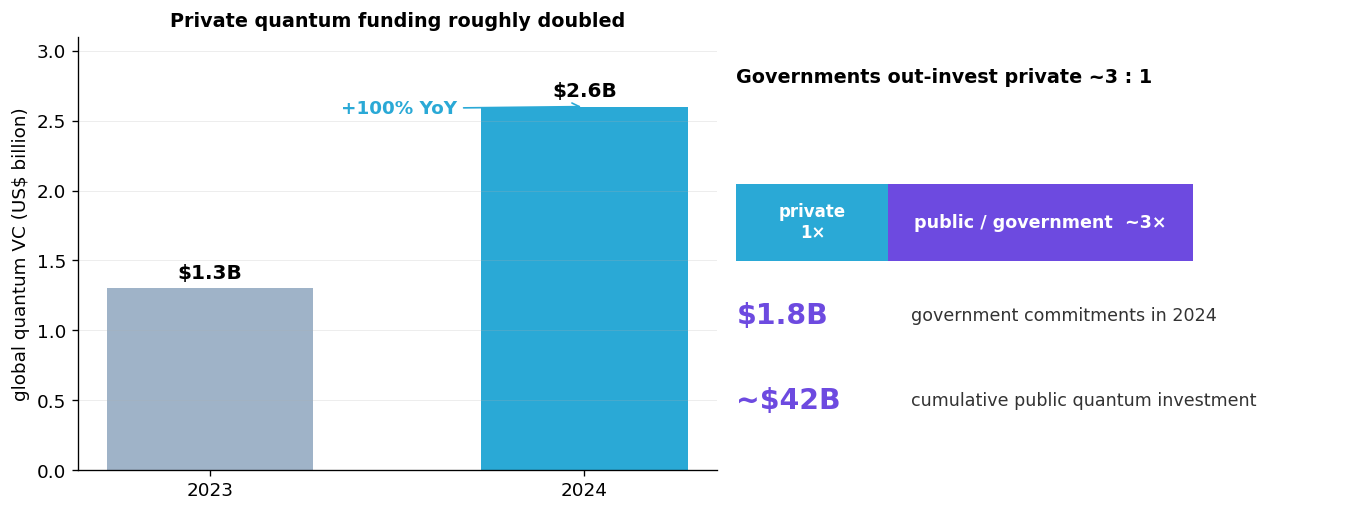

In [2]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={'width_ratios':[1.05,1]})

# (L) VC investment jump 2023 -> 2024
yrs = ['2023', '2024']
vc  = [1.3, 2.6]   # $B global quantum investment volume (McKinsey: 1.3 -> ~2B; VC total ~2.6B)
bars = axL.bar(yrs, vc, color=['#9FB3C8', C_PRIV], width=0.55)
axL.set_ylabel('global quantum VC (US$ billion)')
axL.set_ylim(0, 3.1)
for b,v in zip(bars, vc):
    axL.text(b.get_x()+b.get_width()/2, v+0.07, f'${v:.1f}B', ha='center', fontweight='bold', fontsize=12)
axL.annotate('+100% YoY', xy=(1, 2.6), xytext=(0.35, 2.55), fontsize=11, color=C_PRIV,
             fontweight='bold', arrowprops=dict(arrowstyle='->', color=C_PRIV))
axL.set_title('Private quantum funding roughly doubled', fontsize=11.5, fontweight='bold')
axL.grid(axis='x', alpha=0)

# (R) public vs private split
axR.axis('off')
# stacked ratio bar
axR.barh(0, 3, color=C_GOV, height=0.5)
axR.barh(0, 1, color=C_PRIV, height=0.5)
axR.text(0.5, 0, 'private\n1×', ha='center', va='center', color='white', fontsize=10, fontweight='bold')
axR.text(2.0, 0, 'public / government  ~3×', ha='center', va='center', color='white', fontsize=10.5, fontweight='bold')
axR.set_xlim(0, 4); axR.set_ylim(-1.6, 1.2)
axR.text(0, 0.9, 'Governments out-invest private ~3 : 1', fontsize=11.5, fontweight='bold')
for i,(big,small) in enumerate([('$1.8B','government commitments in 2024'),
                                ('~$42B','cumulative public quantum investment')]):
    axR.text(0.0, -0.6 - i*0.55, big, fontsize=17, fontweight='bold', color=C_GOV, va='center')
    axR.text(1.15, -0.6 - i*0.55, small, fontsize=10.5, color='#333', va='center')

plt.tight_layout()
plt.savefig('fig_quantum_funding.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Quantum-for-cybersecurity — the fastest-growing slice

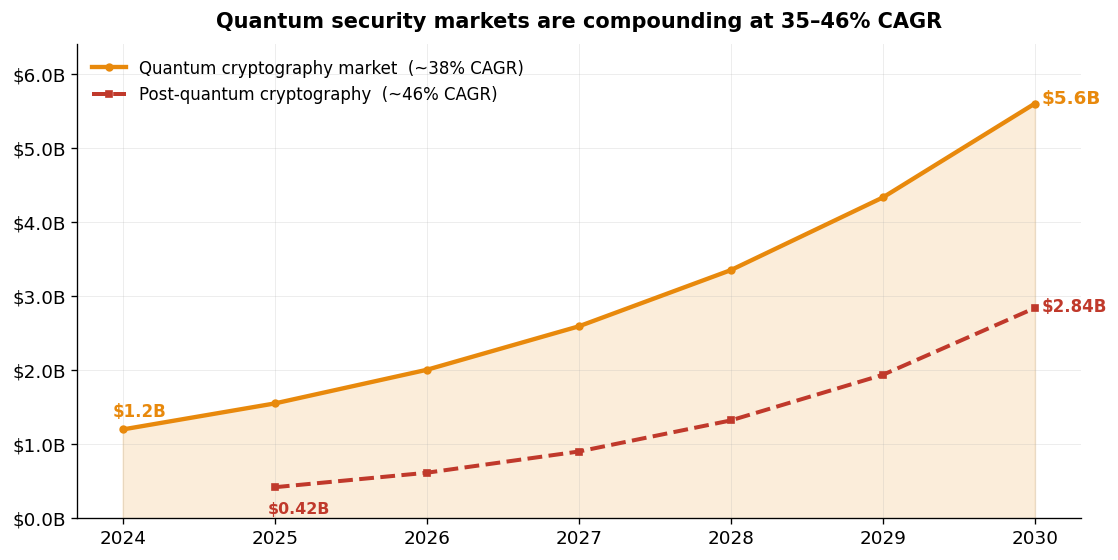

In [3]:
def cagr_curve(v0, v1, y0, y1):
    yrs = np.arange(y0, y1 + 1)
    r = (v1 / v0) ** (1 / (y1 - y0))
    return yrs, v0 * r ** (yrs - y0)

yq, qcrypt = cagr_curve(1.2, 5.6, 2024, 2030)     # quantum cryptography market
yp, pqc    = cagr_curve(0.42, 2.84, 2025, 2030)   # post-quantum cryptography

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.fill_between(yq, qcrypt, color=C_QSEC, alpha=0.15)
ax.plot(yq, qcrypt, color=C_QSEC, lw=2.6, marker='o', ms=4, label='Quantum cryptography market  (~38% CAGR)')
ax.plot(yp, pqc, color=C_PQC, lw=2.4, marker='s', ms=4, ls='--', label='Post-quantum cryptography  (~46% CAGR)')

ax.annotate('$1.2B', (2024, 1.2), textcoords='offset points', xytext=(-6,8), color=C_QSEC, fontweight='bold', fontsize=10)
ax.annotate('$5.6B', (2030, 5.6), textcoords='offset points', xytext=(4,0), color=C_QSEC, fontweight='bold', fontsize=11)
ax.annotate('$0.42B', (2025, 0.42), textcoords='offset points', xytext=(-4,-16), color=C_PQC, fontweight='bold', fontsize=9.5)
ax.annotate('$2.84B', (2030, 2.84), textcoords='offset points', xytext=(4,-2), color=C_PQC, fontweight='bold', fontsize=10)

ax.set_ylim(0, 6.4); ax.yaxis.set_major_formatter(usdB)
ax.set_xticks(range(2024, 2031))
ax.set_title('Quantum security markets are compounding at 35–46% CAGR',
             fontsize=12.5, fontweight='bold', pad=10)
ax.legend(frameon=False, loc='upper left', fontsize=10)
plt.tight_layout()
plt.savefig('fig_quantum_security_market.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Positioning — where QORC sits

Most quantum-security money today targets **encryption** (protecting data against
future quantum computers). QORC targets a different, under-funded axis: using
quantum hardware to **detect** attacks. Adjacent to a fast-growing market, with
less crowding.

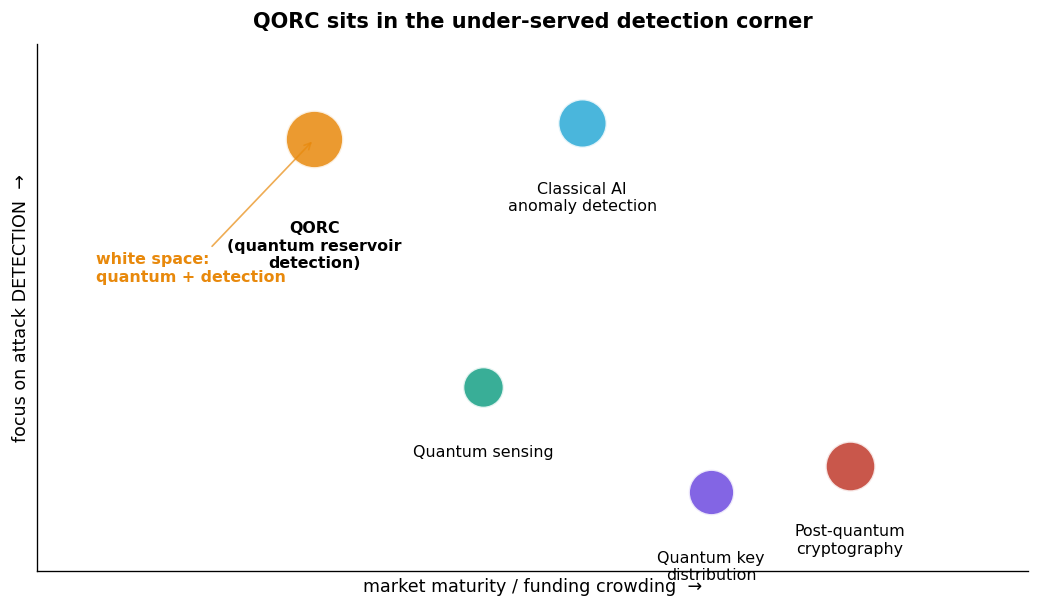

In [4]:
fig, ax = plt.subplots(figsize=(8.8, 5.2))
# x = market maturity/funding, y = defensive detection focus
pts = {
    'Post-quantum\ncryptography': (0.82, 0.20, C_PQC, 900),
    'Quantum key\ndistribution':  (0.68, 0.15, C_GOV, 750),
    'Quantum sensing':            (0.45, 0.35, '#16A085', 600),
    'Classical AI\nanomaly detection': (0.55, 0.85, C_PRIV, 850),
    'QORC\n(quantum reservoir\ndetection)': (0.28, 0.82, C_QSEC, 1200),
}
for name,(x,y,c,s) in pts.items():
    ax.scatter(x, y, s=s, color=c, alpha=0.85, edgecolor='white', linewidth=1.5, zorder=3)
    ax.text(x, y-0.11 if 'QORC' not in name else y-0.155, name, ha='center', va='top',
            fontsize=9.5, fontweight='bold' if 'QORC' in name else 'normal', zorder=4)

ax.annotate('white space:\nquantum + detection',
            xy=(0.28, 0.82), xytext=(0.06, 0.55), fontsize=9.5, color=C_QSEC,
            fontweight='bold',
            arrowprops=dict(arrowstyle='->', color=C_QSEC, alpha=0.7))

ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel('market maturity / funding crowding  →', fontsize=10.5)
ax.set_ylabel('focus on attack DETECTION  →', fontsize=10.5)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title('QORC sits in the under-served detection corner', fontsize=12.5, fontweight='bold', pad=10)
ax.grid(alpha=0.15)
plt.tight_layout()
plt.savefig('fig_quantum_positioning.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
print('QUANTUM INVESTMENT  —  takeaways')
print('='*52)
print('  $1.3B → $2.6B   global quantum VC (2023→2024, ~2×)')
print('  $1.8B / yr      government quantum commitments (2024)')
print('  ~$42B           cumulative announced public investment')
print('  ~3 : 1          public-to-private funding ratio')
print('  $1.2B → $5.6B   quantum cryptography market (2024→2030, ~38% CAGR)')
print('  $0.42B→ $2.84B  post-quantum cryptography (2025→2030, ~46% CAGR)')
print()
print('  POSITIONING: capital is pouring into quantum, but mostly into ENCRYPTION.')
print('               QORC targets quantum-enhanced DETECTION — adjacent, less crowded.')

QUANTUM INVESTMENT  —  takeaways
  $1.3B → $2.6B   global quantum VC (2023→2024, ~2×)
  $1.8B / yr      government quantum commitments (2024)
  ~$42B           cumulative announced public investment
  ~3 : 1          public-to-private funding ratio
  $1.2B → $5.6B   quantum cryptography market (2024→2030, ~38% CAGR)
  $0.42B→ $2.84B  post-quantum cryptography (2025→2030, ~46% CAGR)

  POSITIONING: capital is pouring into quantum, but mostly into ENCRYPTION.
               QORC targets quantum-enhanced DETECTION — adjacent, less crowded.
